# 32 — 2021 model comparison, with Delta and Omicron calendar context

2021only. Same585ZIPs,362origins Jan1–Dec28, all1/2/3day targets end byDec31. Original34candidates includingPressure,60-day rolling training,weekly refits. Original2020calibrated MA3warning rule unchanged. No budget analysis.

Focus windows:Delta-associated summer (Jul1–Sep27 origins,targets<=Sep30),Omicron emergence (Dec1–Dec28 origins,targets<=Dec31). December covers earlyOmicron and mixedDelta/Omicron transition, not the fullwave or2022peak. Calendar context is not individual variant attribution. CDC:https://www.cdc.gov/mmwr/volumes/71/wr/mm7106a4.htm

2022–2023outcomes excluded from this notebook and output package. Prior2021exploration prevents an untouched-test claim.

Results have already been calculated. Run the final cell only to inspect. Full retraining is optional and can take substantial time. Requires numpy,pandas,scipy,matplotlib,sklearn1.9.0 andxgboost3.4.1 (original versions).

In [6]:
from pathlib import Path
import importlib.util,json
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir():ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"later_time_evaluation_outputs"/"evaluation_2021_20261101"
SUPPORT=OUTPUT/"support"
def load_module(name):
    spec=importlib.util.spec_from_file_location(name,SUPPORT/(name+".py"))
    module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module
print(OUTPUT.resolve())

C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\later_time_evaluation_outputs\evaluation_2021_20261101


## Fixed settings
No feature selection or parameter tuning on2021results. Every supervised target must mature by fit date. Predictor history updates daily; parameters refit on the original7-day schedule.14warmup days remain inside each60-day window. RF computation uses16threads rather than4, with identical statistical settings and seed. ZIP identity representations remain estimator-specific. Original warning threshold0, event confirmation on second qualifying day,7day reset and cooldown.

The three-month Delta and one-month December periods have different lengths and case activity. Compare model rankings within each period, and report event counts and positive shares. AP is not accuracy; strict-flat direction requires exactly equal endpoints. CIs below describe differences in mean errors, not intervals for future daily cases.

In [7]:
from IPython.display import display
display(json.loads((OUTPUT/"frozen_plan.json").read_text(encoding="utf-8")))

{'initial_training': ['2020-03-01', '2020-04-29'],
 'evaluation_origins': ['2021-01-01', '2021-12-28'],
 'window_days': 60,
 'retrain_days': 7,
 'horizons': [1, 2, 3],
 'candidate_features': 34,
 'regions': 585,
 'event_definition': 'Notebook27 MA3 unchanged',
 'warning_thresholds': {'Dynamic Panel FE': 0,
  'XGBoost': 0,
  'Random Forest': 0},
 'warning_cooldown_days': 7,
 'no_tuning_on_evaluation': True,
 'prior_exploration_disclosed': True,
 'source_sha256': 'd18a70fe1b1efa550c0bc3e28edeca576f432996dfc85d67106c70069f79a9e4',
 'cohort_sha256': '2c53373ea2e9fe169d69985e558ea2eb5d9bd790601e4f5c56ebe60e56dfbc67',
 'storage': 'weekly resumable prediction checkpoints; estimator files not persisted, fixed original fitting rules and seeds retained',
 'compute_only_change': 'Random Forest n_jobs16 vs original4, same200trees,seed,features and statistical parameters; no estimator files saved. Parallelism can introduce tiny floating-point summation differences.',
 'evaluation_origin_count': 362

## Optional: reproduce 2021 forecasts
Skip completed archives. Incomplete retraining resumes weekly checkpoints. No2022–2023training or forecasts occur in these restricted runners.

In [8]:
SOURCE=ROOT/'rolling_trajectory_outputs/inputs/nj_daily_features.csv.gz'
COHORT=ROOT/'fixed60_trajectory_outputs/fixed60_20261027/common_regions.csv'
for name,function in [('dynamic_panel','run_rolling60'),('xgboost','run_xgboost60'),('random_forest','run_random_forest60')]:
    destination=OUTPUT/name
    if (destination/'predictions.npz').exists():
        print('Reuse completed2021archive:',name)
        continue
    module=load_module(name+'_evaluation')
    getattr(module,function)(SOURCE,COHORT,destination,stage='evaluation',evaluation_plan_frozen=True)

Reuse completed2021archive: dynamic_panel
Reuse completed2021archive: xgboost
Reuse completed2021archive: random_forest


## Reproduce the matched comparison and focus-window analysis
Bootstrap resamples common date blocks, retaining all ZIPs together. Warning thresholds are not reselected. Phase-specific warnings preserve the original full2021cooldown; selected phase event denominators require an eligible forecast in that phase. FocusHAC pvalues are exploratory withHolm correction across6planned contrasts. No causal interpretation.

In [9]:
analysis=load_module("run_2021_analysis")
scorecard=analysis.analyze(ROOT,OUTPUT)
display(scorecard)

Warning analysis finished: Dynamic Panel FE
Warning analysis finished: XGBoost
Warning analysis finished: Random Forest
           model                  period  trajectory_MAE       AP  events  event_recall  warning_precision
Dynamic Panel FE               Full 2021        1.107401 0.518445    2752      0.805596           0.732166
Dynamic Panel FE Delta-associated period        0.903360 0.521343     791      0.780025           0.761728
Dynamic Panel FE       Omicron emergence        2.395511 0.591606     475      0.840000           0.585903
         XGBoost               Full 2021        1.098323 0.528637    2752      0.763808           0.827885
         XGBoost Delta-associated period        0.878156 0.520073     791      0.729456           0.825465
         XGBoost       Omicron emergence        2.305367 0.626145     475      0.812632           0.844639
   Random Forest               Full 2021        1.090408 0.544281    2752      0.804506           0.773315
   Random Forest Delta-a

,model,period,origin_start,origin_end,last_target,origins,regions,paths,trajectory_MAE,RMSE,...,AP,positive_origin_share,events,detected_events,event_recall,warnings,warning_precision,mean_lead_days,recall_at_least_2_days,MAE_improvement_vs_DP_percent
0,Dynamic Panel FE,Full 2021,2021-01-01,2021-12-28,2021-12-31,362,585,211770,1.107401,1.901808,...,0.518445,0.045140,2752,2217,0.805596,3028,0.732166,1.237709,0.157703,0.000000
1,Dynamic Panel FE,Delta-associated period,2021-07-01,2021-09-27,2021-09-30,89,585,52065,0.903360,1.335991,...,0.521343,0.054342,791,617,0.780025,810,0.761728,1.141005,0.092288,0.000000
2,Dynamic Panel FE,Omicron emergence,2021-12-01,2021-12-28,2021-12-31,28,585,16380,2.395511,3.894977,...,0.591606,0.148823,475,399,0.840000,681,0.585903,1.553885,0.357895,0.000000
3,XGBoost,Full 2021,2021-01-01,2021-12-28,2021-12-31,362,585,211770,1.098323,1.939047,...,0.528637,0.045140,2752,2102,0.763808,2539,0.827885,1.107517,0.074855,0.819737
4,XGBoost,Delta-associated period,2021-07-01,2021-09-27,2021-09-30,89,585,52065,0.878156,1.355764,...,0.520073,0.054342,791,577,0.729456,699,0.825465,1.067591,0.042984,2.790100
5,XGBoost,Omicron emergence,2021-12-01,2021-12-28,2021-12-31,28,585,16380,2.305367,4.110713,...,0.626145,0.148823,475,386,0.812632,457,0.844639,1.142487,0.107368,3.763020
6,Random Forest,Full 2021,2021-01-01,2021-12-28,2021-12-31,362,585,211770,1.090408,1.900485,...,0.544281,0.045140,2752,2214,0.804506,2863,0.773315,1.200090,0.139535,1.534479
7,Random Forest,Delta-associated period,2021-07-01,2021-09-27,2021-09-30,89,585,52065,0.890599,1.348418,...,0.536163,0.054342,791,623,0.787611,815,0.764417,1.181380,0.117573,1.412630
8,Random Forest,Omicron emergence,2021-12-01,2021-12-28,2021-12-31,28,585,16380,2.285973,3.964947,...,0.644166,0.148823,475,398,0.837895,515,0.772816,1.329146,0.237895,4.572652


## Read saved results without rerunning
Run this cell directly in a fresh kernel.

# Notebook32：2021年整体及Delta/Omicron时间段比较



## 先看这三项

1. focus_period_scorecard.csv：2021整体、Delta相关夏季窗口和12月Omicron出现窗口的模型成绩。

2. figures/02_focus_period_comparison.png：重点时期的MAE、AP、检出率和预警正确比例。

3. figures/01_2021_errors_and_activity.png：全年病例活动与预测误差走势。



## 如何划分

全年origin为2021年1月1日—12月28日，共362天，585地区，211770条三天路径。所有target都在2021年内。Delta相关阶段采用7月1日—9月27日的预测，目标截至9月30日；Omicron出现阶段采用12月1日—28日的预测，目标截至12月31日。

CDC将美国主要病例激增概括为Delta2021年7—9月、Omicron2021年12月—2022年1月。我们只看2021，所以12月不能代表完整Omicron波，且月初仍有Delta传播。这只是全国日历背景，不是每条NJ病例的变异株标记。

CDC source: https://www.cdc.gov/mmwr/volumes/71/wr/mm7106a4.htm



## 结果

           model                  period  origins  trajectory_MAE     RMSE  direction_agreement       AP  events  event_recall  warning_precision  mean_lead_days  recall_at_least_2_days
Dynamic Panel FE               Full 2021      362        1.107401 1.901808             0.362837 0.518445    2752      0.805596           0.732166        1.237709                0.157703
Dynamic Panel FE Delta-associ

,model,period,origin_start,origin_end,last_target,origins,regions,paths,trajectory_MAE,RMSE,...,AP,positive_origin_share,events,detected_events,event_recall,warnings,warning_precision,mean_lead_days,recall_at_least_2_days,MAE_improvement_vs_DP_percent
0,Dynamic Panel FE,Full 2021,2021-01-01,2021-12-28,2021-12-31,362,585,211770,1.107401,1.901808,...,0.518445,0.045140,2752,2217,0.805596,3028,0.732166,1.237709,0.157703,0.000000
1,Dynamic Panel FE,Delta-associated period,2021-07-01,2021-09-27,2021-09-30,89,585,52065,0.903360,1.335991,...,0.521343,0.054342,791,617,0.780025,810,0.761728,1.141005,0.092288,0.000000
2,Dynamic Panel FE,Omicron emergence,2021-12-01,2021-12-28,2021-12-31,28,585,16380,2.395511,3.894977,...,0.591606,0.148823,475,399,0.840000,681,0.585903,1.553885,0.357895,0.000000
3,XGBoost,Full 2021,2021-01-01,2021-12-28,2021-12-31,362,585,211770,1.098323,1.939047,...,0.528637,0.045140,2752,2102,0.763808,2539,0.827885,1.107517,0.074855,0.819737
4,XGBoost,Delta-associated period,2021-07-01,2021-09-27,2021-09-30,89,585,52065,0.878156,1.355764,...,0.520073,0.054342,791,577,0.729456,699,0.825465,1.067591,0.042984,2.790100
5,XGBoost,Omicron emergence,2021-12-01,2021-12-28,2021-12-31,28,585,16380,2.305367,4.110713,...,0.626145,0.148823,475,386,0.812632,457,0.844639,1.142487,0.107368,3.763020
6,Random Forest,Full 2021,2021-01-01,2021-12-28,2021-12-31,362,585,211770,1.090408,1.900485,...,0.544281,0.045140,2752,2214,0.804506,2863,0.773315,1.200090,0.139535,1.534479
7,Random Forest,Delta-associated period,2021-07-01,2021-09-27,2021-09-30,89,585,52065,0.890599,1.348418,...,0.536163,0.054342,791,623,0.787611,815,0.764417,1.181380,0.117573,1.412630
8,Random Forest,Omicron emergence,2021-12-01,2021-12-28,2021-12-31,28,585,16380,2.285973,3.964947,...,0.644166,0.148823,475,398,0.837895,515,0.772816,1.329146,0.237895,4.572652


,model,period,horizon,MAE,RMSE
0,Dynamic Panel FE,Full 2021,1,1.075210,1.808394
1,Dynamic Panel FE,Full 2021,2,1.107571,1.901586
2,Dynamic Panel FE,Full 2021,3,1.139423,1.991056
3,Dynamic Panel FE,Delta-associated period,1,0.883296,1.312083
4,Dynamic Panel FE,Delta-associated period,2,0.902547,1.334763
5,Dynamic Panel FE,Delta-associated period,3,0.924238,1.360684
6,Dynamic Panel FE,Omicron emergence,1,2.125709,3.375062
7,Dynamic Panel FE,Omicron emergence,2,2.385450,3.871204
8,Dynamic Panel FE,Omicron emergence,3,2.675374,4.374388
9,XGBoost,Full 2021,1,1.075307,1.872335


,period,reference,candidate,MAE_improvement,ci95_low,ci95_high,block_days,dates
0,Delta-associated period,Dynamic Panel FE,XGBoost,0.025205,0.012617,0.040323,7,89
1,Delta-associated period,Dynamic Panel FE,XGBoost,0.025205,0.009796,0.044727,14,89
2,Delta-associated period,Dynamic Panel FE,Random Forest,0.012761,-0.000958,0.026385,7,89
3,Delta-associated period,Dynamic Panel FE,Random Forest,0.012761,-0.004637,0.031831,14,89
4,Delta-associated period,XGBoost,Random Forest,-0.012444,-0.019126,-0.008029,7,89
5,Delta-associated period,XGBoost,Random Forest,-0.012444,-0.018210,-0.009201,14,89
6,Omicron emergence,Dynamic Panel FE,XGBoost,0.090144,-0.159803,0.129681,7,28
7,Omicron emergence,Dynamic Panel FE,XGBoost,0.090144,-0.137713,0.090144,14,28
8,Omicron emergence,Dynamic Panel FE,Random Forest,0.109538,-0.020569,0.157396,7,28
9,Omicron emergence,Dynamic Panel FE,Random Forest,0.109538,0.007913,0.109538,14,28


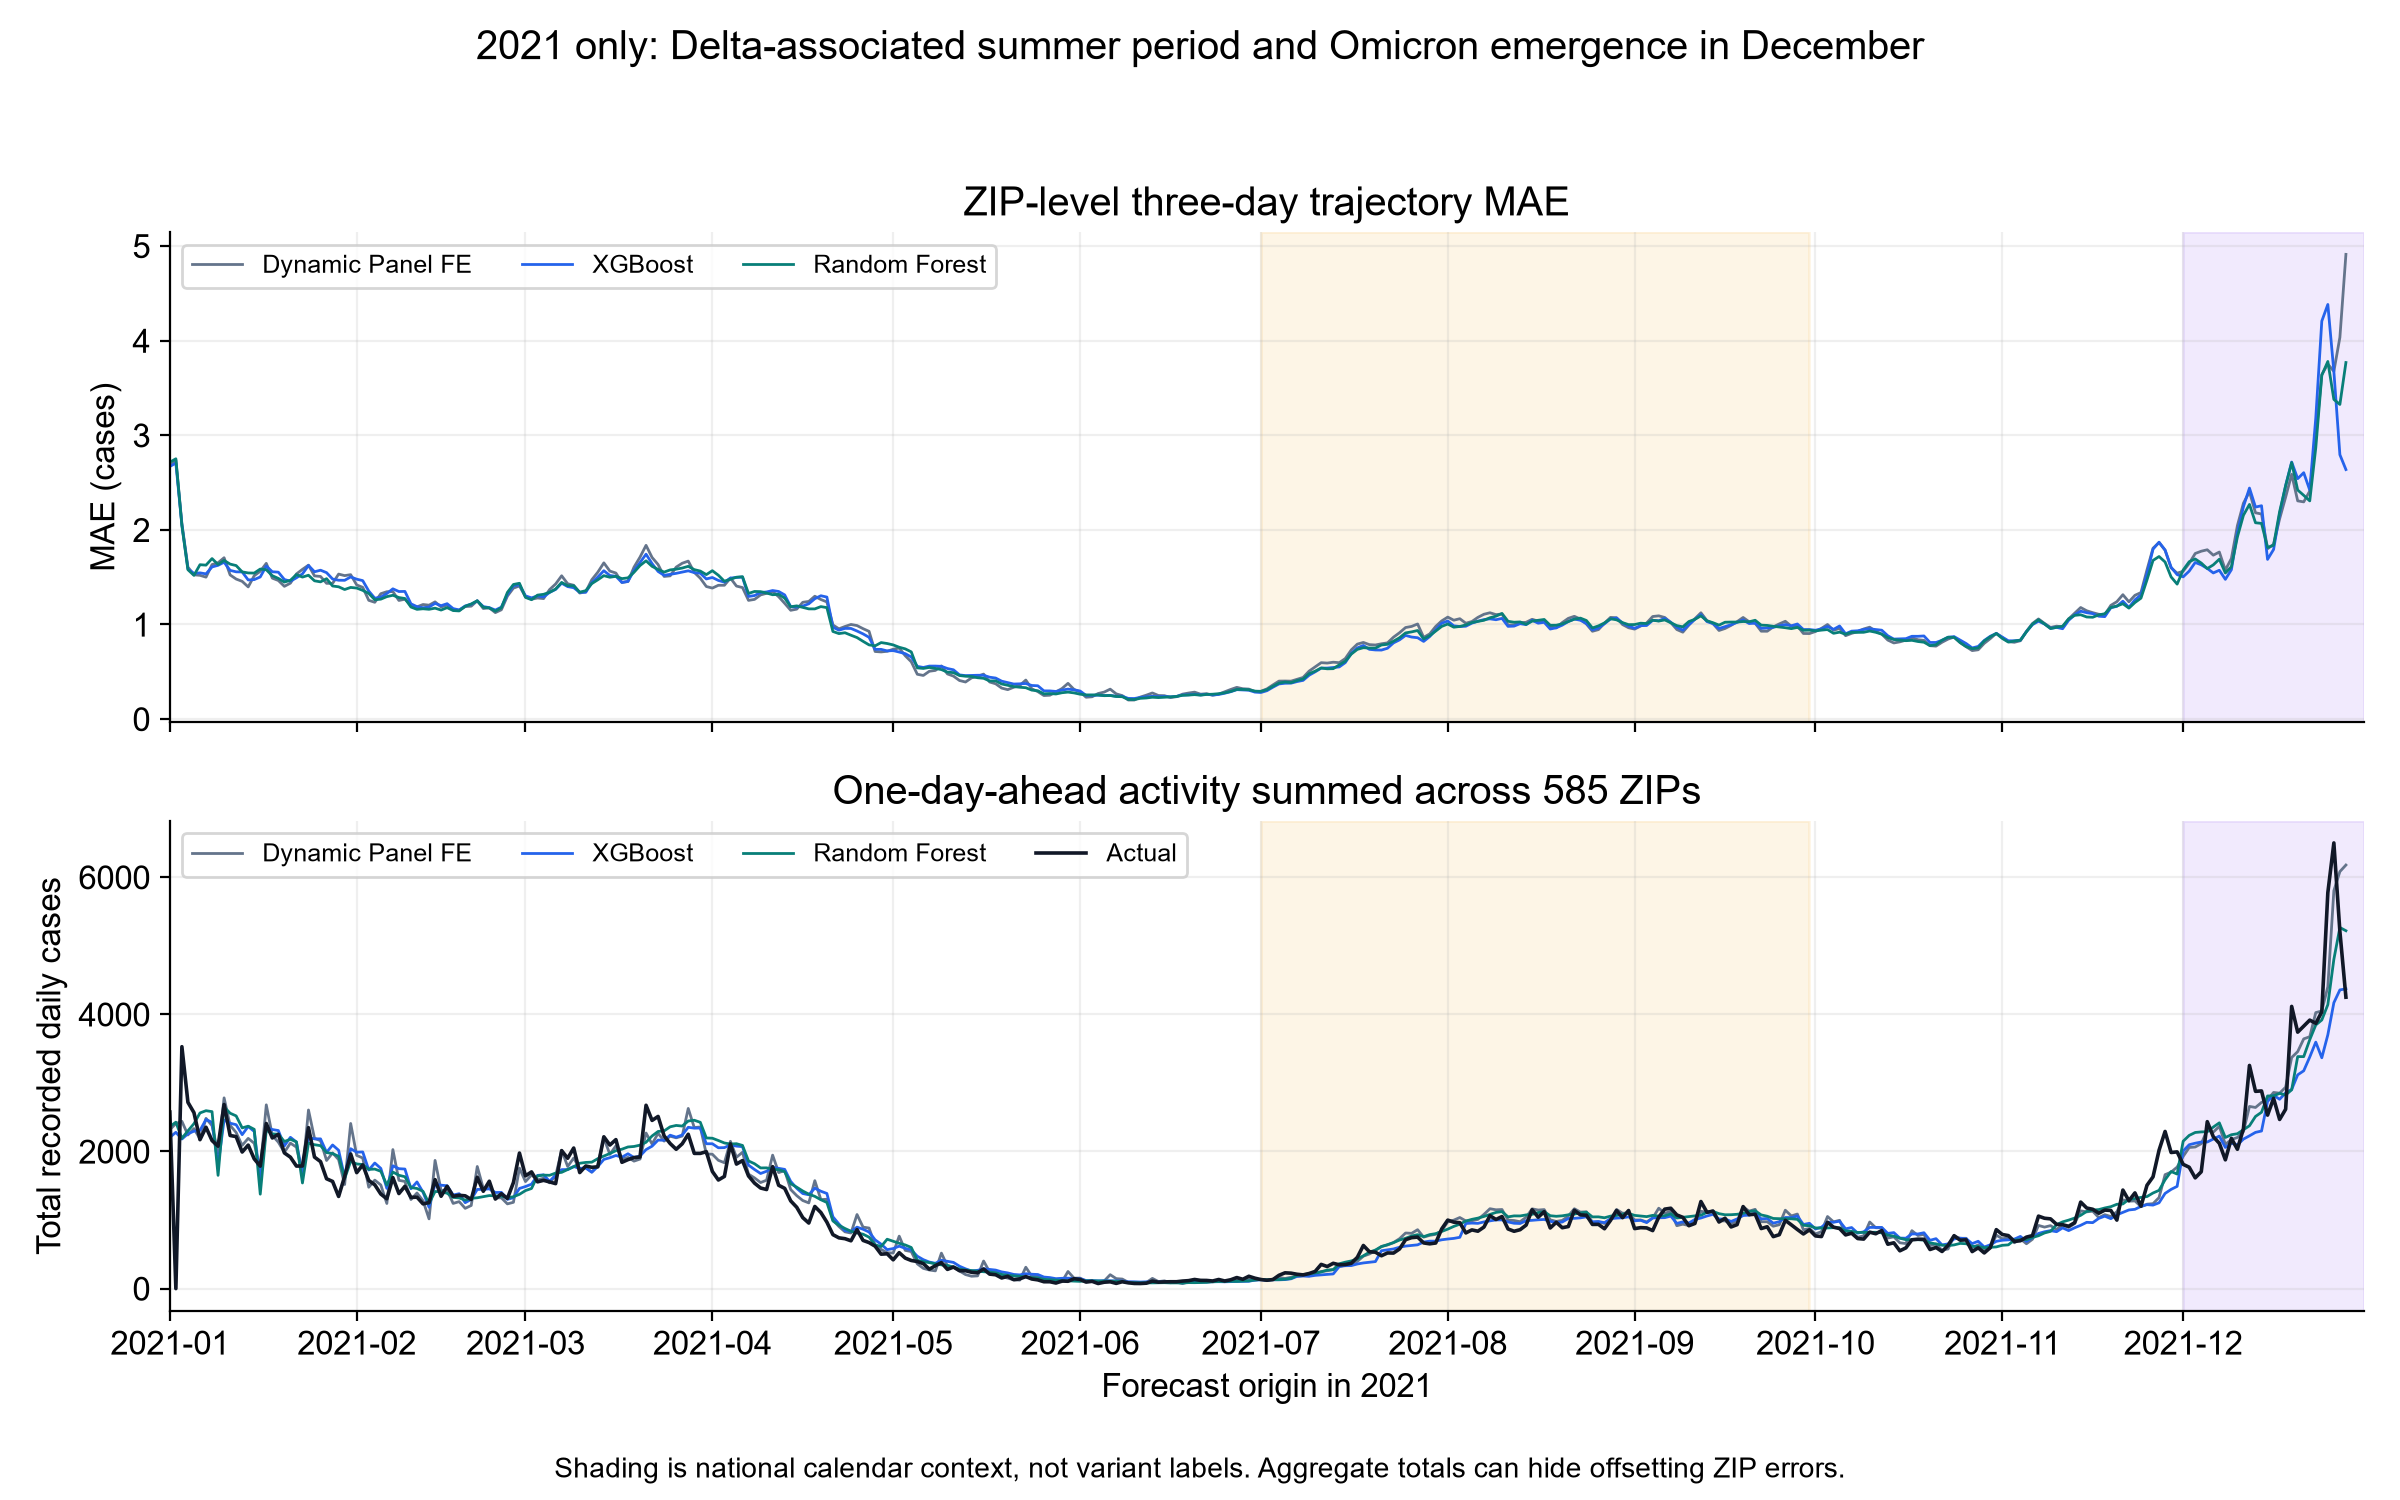

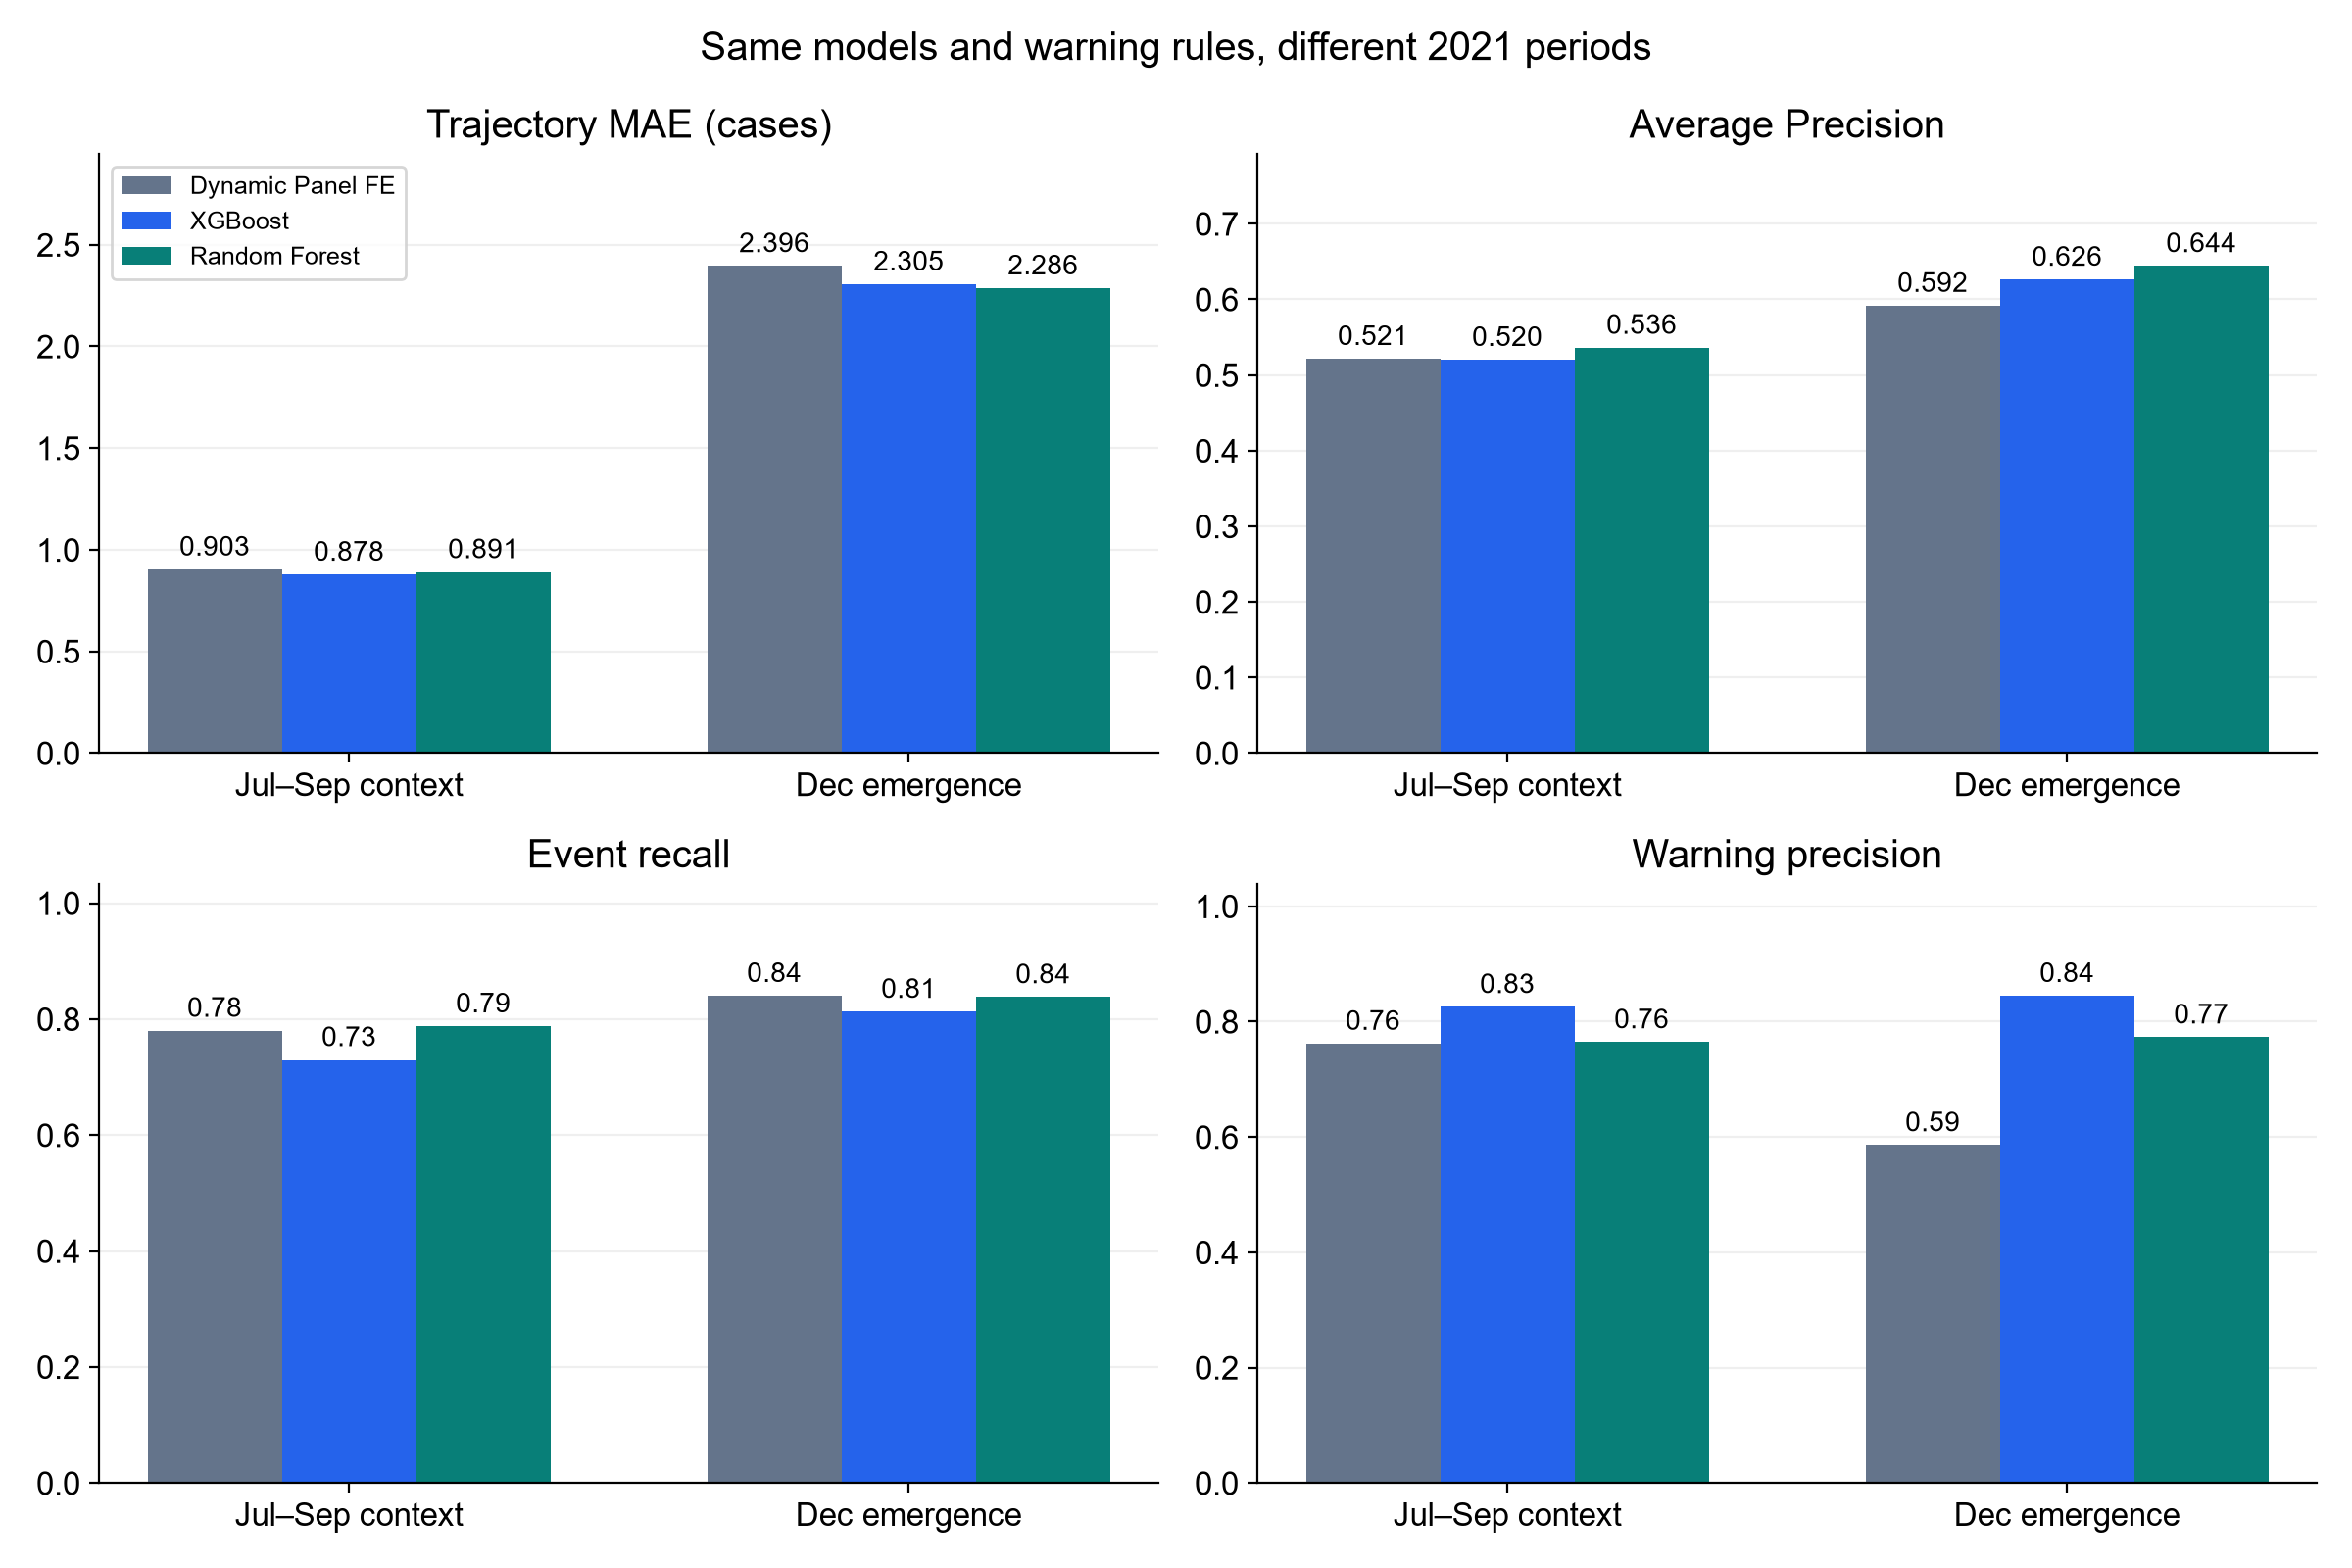

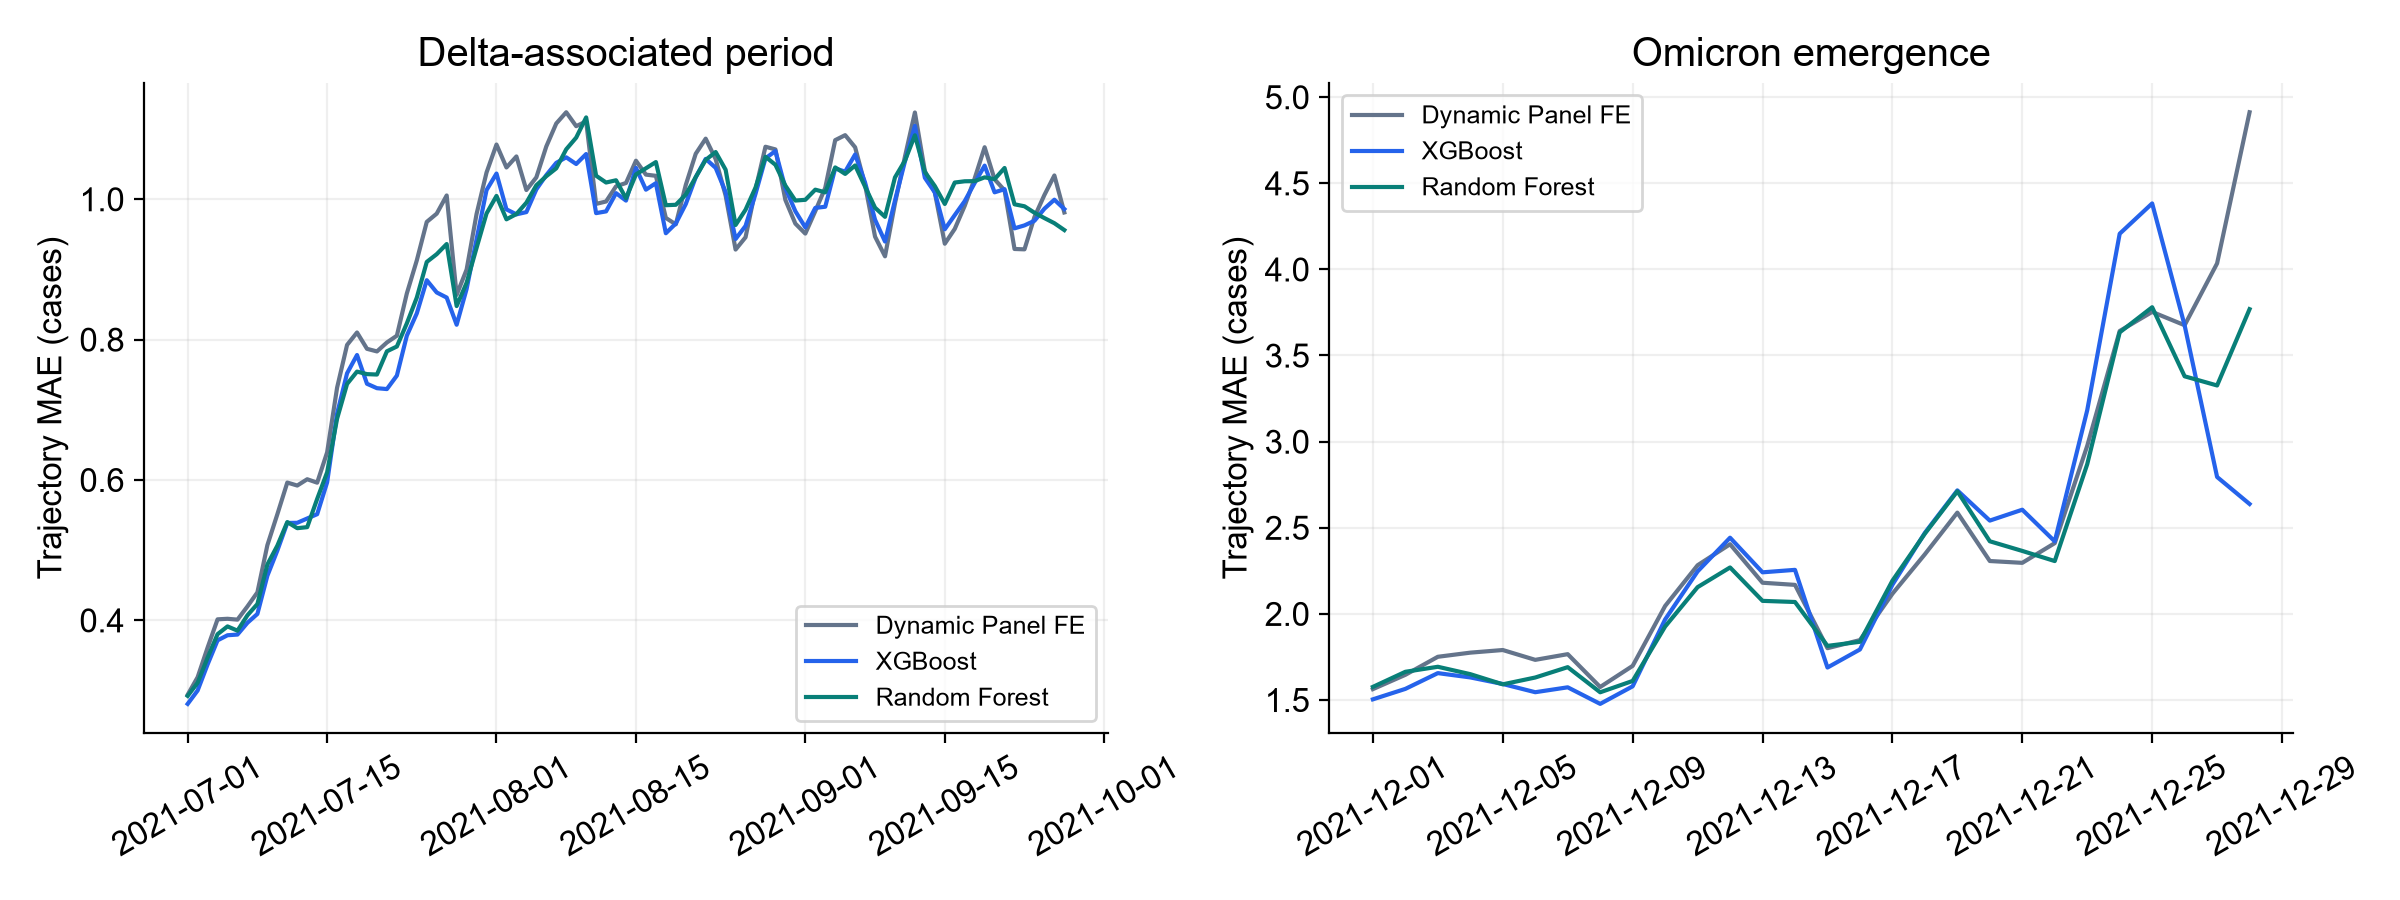

In [10]:
from pathlib import Path
import pandas as pd
from IPython.display import display,Image
SAVED_ROOT=Path.cwd()
if (SAVED_ROOT/'Weikun').is_dir():SAVED_ROOT=SAVED_ROOT/'Weikun'
SAVED=SAVED_ROOT/'later_time_evaluation_outputs'/'evaluation_2021_20261101'
print((SAVED/'START_HERE_CN.md').read_text(encoding='utf-8'))
display(pd.read_csv(SAVED/'focus_period_scorecard.csv'))
display(pd.read_csv(SAVED/'focus_horizon_metrics.csv'))
display(pd.read_csv(SAVED/'focus_MAE_date_block_intervals.csv'))
for name in ['01_2021_errors_and_activity.png','02_focus_period_comparison.png','03_delta_omicron_error_detail.png']:
    display(Image(filename=str(SAVED/'figures'/name)))


## Integrated evaluation metrics: 2021 spatial errors and warning lead time

Read `integrated_metrics/unified_evaluation_scorecard.csv` for count/trajectory metrics, AP, event recall, warning precision, lead time and horizon-specific residual Moran’s I.

Moran’s I uses the same geographic graph as Notebook24: symmetric union of 8 nearest neighbors, then row standardization. It examines all585ZIP residuals separately at each date/horizon.999permutations. Primary BH family spans all3258model-date-horizon tests. Per-model BH results remain in individual folders, with different adjustment scope.

Mean I is descriptive and has no pooled p-value. No paired test establishes superiority in I. Geographic mapping is an exact identifier match, still unvalidated. Count heteroskedasticity can undermine permutation exchangeability.

Warning lead time refers to event confirmation on the second qualifying day. A one-day warning may already use the first abnormal day. Report missed events alongside lead time. No model refit or changed forecasts.


In [11]:
# Read already-computed diagnostics. No retraining.
import pandas as pd
metrics = pd.read_csv(OUTPUT / "integrated_metrics" / "unified_evaluation_scorecard.csv")
display(metrics.loc[metrics.period.eq("Full 2021"), ["model", "trajectory_MAE", "AP", "event_recall", "warning_precision", "mean_lead_days", "median_lead_days", "Moran_I_h1", "Moran_I_h2", "Moran_I_h3"]])
display(pd.read_csv(OUTPUT / "integrated_metrics" / "residual_moran_period_summary.csv"))


,model,trajectory_MAE,AP,event_recall,warning_precision,mean_lead_days,median_lead_days,Moran_I_h1,Moran_I_h2,Moran_I_h3
0,Dynamic Panel FE,1.107401,0.518445,0.805596,0.732166,1.237709,1.0,0.027663,0.034839,0.041203
3,XGBoost,1.098323,0.528637,0.763808,0.827885,1.107517,1.0,0.022329,0.027596,0.032781
6,Random Forest,1.090408,0.544281,0.804506,0.773315,1.200090,1.0,0.020579,0.026847,0.031789


,model,period,horizon,dates,mean_Moran_I,median_Moran_I,BH_significant_share,positive_BH_significant_share
0,Dynamic Panel FE,Full 2021,1,362,0.027663,0.017746,0.207182,0.204420
1,Dynamic Panel FE,Full 2021,2,362,0.034839,0.021569,0.245856,0.243094
2,Dynamic Panel FE,Full 2021,3,362,0.041203,0.025594,0.287293,0.287293
3,Random Forest,Full 2021,1,362,0.020579,0.016071,0.174033,0.165746
4,Random Forest,Full 2021,2,362,0.026847,0.019101,0.204420,0.198895
5,Random Forest,Full 2021,3,362,0.031789,0.022705,0.234807,0.232044
6,XGBoost,Full 2021,1,362,0.022329,0.017884,0.157459,0.154696
7,XGBoost,Full 2021,2,362,0.027596,0.019915,0.190608,0.187845
8,XGBoost,Full 2021,3,362,0.032781,0.022593,0.226519,0.223757
9,Dynamic Panel FE,Delta-associated period,1,89,0.014851,0.014209,0.123596,0.112360


In [12]:
# Optional: rerun diagnostics from saved2021predictions only.
# module = load_module("integrated_metrics")
# module.run(OUTPUT, ROOT / "rolling_trajectory_outputs" / "inputs" / "2021_Gaz_zcta_national.txt")


## Trajectory evaluation priority: endpoint direction

We use endpoint direction agreement as the primary measure of trajectory direction, with strict two-step shape agreement as a supplementary diagnostic.

Primary: compare sign(Day3 − Day1) for predicted and actual paths. Day1 and Day3 are future horizons t+1 and t+3. Rising, declining, and exact endpoint-flat remain unchanged. No wider flat tolerance.

Supplementary: both Day2−Day1 and Day3−Day2 signs must match. MAE/RMSE remain count-level metrics.

This is a change in evaluation emphasis after inspecting results, not a retrained or improved model. No forecasts, warning rules or other metrics change. All model endpoint accuracies remain below the42.4% always-flat reference, so report class-specific or balanced accuracy alongside overall agreement.


In [ ]:
# Existing predictions, updated reporting priority only.
display(pd.read_csv(OUTPUT / "integrated_metrics" / "trajectory_direction_primary_summary.csv"))
